# 02 · Baseline similarity (Week 4)
BLEU-4, ROUGE-L (wording kept) and BERTScore, SBERT (meaning kept) for T1–T3 against T0,
700 Human documents. Produced by `python -m src.run_baseline --all`.

In [1]:
import os, sys
ROOT = os.path.abspath("..")          # notebooks/ -> repository root
sys.path.insert(0, ROOT)
os.chdir(ROOT)
import pandas as pd
pd.set_option("display.max_colwidth", 120)

In [2]:
comp = pd.read_csv("experiments/baseline_results/paraphraser_comparison.csv")
comp[comp.generation == "T3"].sort_values("sbert_cosine", ascending=False)

,paraphraser,generation,bleu,rouge_l,bertscore_f1,bertscore_rescaled,sbert_cosine
27,pegasus(slight),T3,0.6434,0.8104,0.9433,0.8301,0.9246
15,dipper(low),T3,0.3057,0.5613,0.9051,0.7156,0.8893
7,palm,T3,0.2772,0.5406,0.8861,0.6588,0.8755
3,chatgpt,T3,0.1368,0.4249,0.8638,0.5918,0.8754
23,pegasus(full),T3,0.2365,0.5300,0.8696,0.6092,0.8197
31,wordnet,T3,0.4002,0.7562,0.8991,0.6977,0.7854
11,dipper,T3,0.0581,0.2466,0.8201,0.4609,0.7240
19,dipper(high),T3,0.0034,0.0891,0.6784,0.0365,0.0563


## Decay across generations for ChatGPT

In [3]:
comp[comp.paraphraser == "chatgpt"]

,paraphraser,generation,bleu,rouge_l,bertscore_f1,bertscore_rescaled,sbert_cosine
0,chatgpt,T0,1.0000,1.0000,1.0000,1.0000,1.0000
1,chatgpt,T1,0.1923,0.5057,0.8842,0.6530,0.8998
2,chatgpt,T2,0.1640,0.4606,0.8715,0.6150,0.8840
3,chatgpt,T3,0.1368,0.4249,0.8638,0.5918,0.8754


## Wording kept vs. meaning kept, all paraphrasers

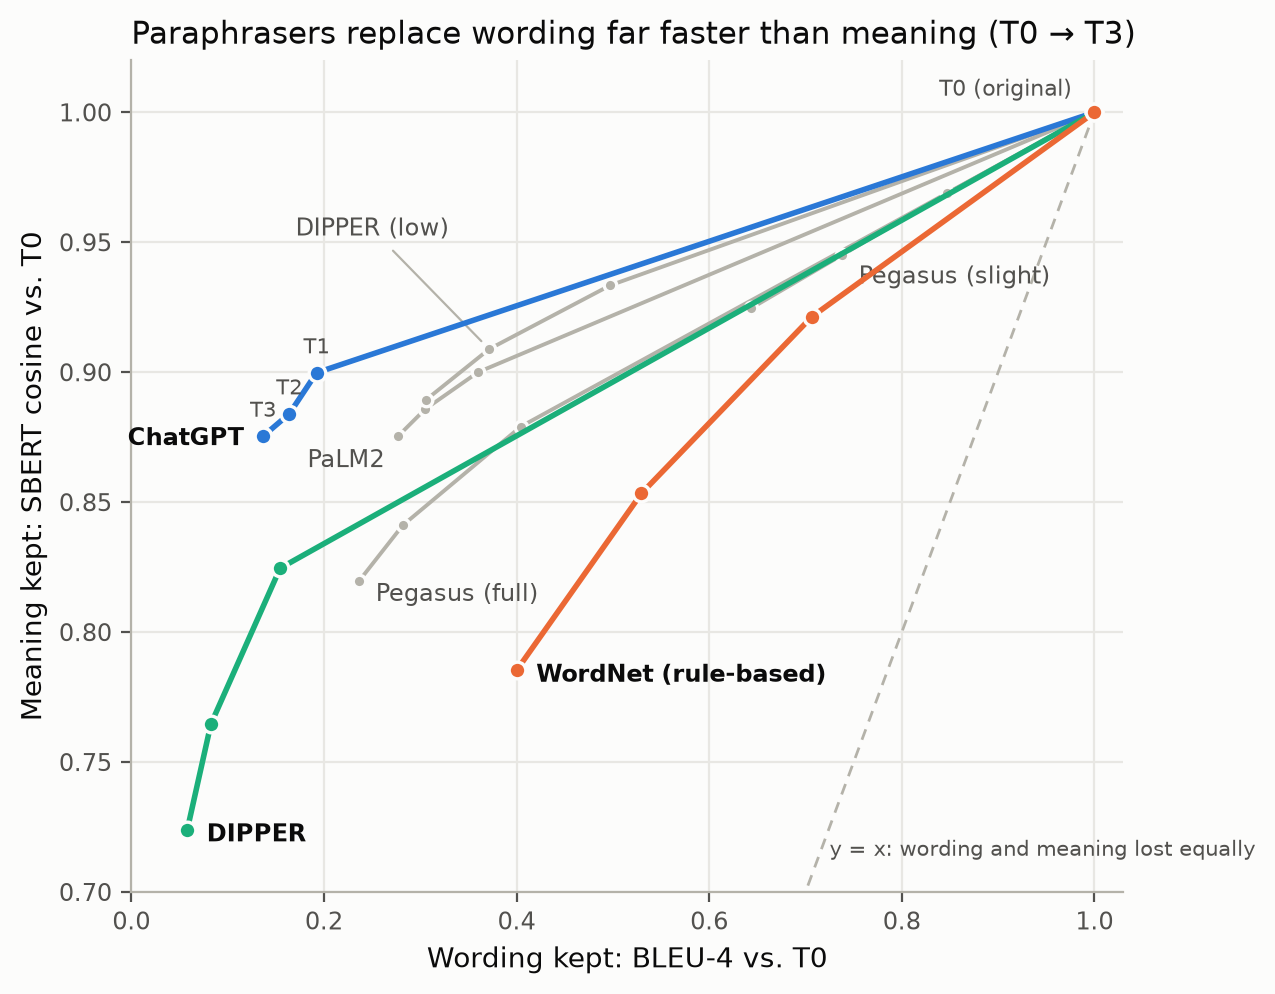

In [4]:
from IPython.display import Image
Image("figures/decay_curves/paraphraser_trajectories.png", width=650)